#### Import the libraries:


In [1]:
import os; os.chdir("..")
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from ml.evaluate import load_splits, make_preprocessor, evaluate, FEATURES

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay



In [2]:
S = load_splits()
Xtr, ytr = S["train"][FEATURES], S["train"]["target"]
Xva, yva = S["val"][FEATURES], S["val"]["target"]

In [3]:
models = {
    # this "No correction:" shows the "predict no for everyone" trap
    "LR (no correction)": Pipeline([("prep", make_preprocessor()),
                                    ("model", LogisticRegression(max_iter=2000))]),
    # and Primary method from the proposal
    "LR (class weights)": Pipeline([("prep", make_preprocessor()),
                                    ("model", LogisticRegression(class_weight="balanced", max_iter=2000))]),
    # Alternative: SMOTE, applied inside the pipeline so it only touches training folds
    "LR (SMOTE)": ImbPipeline([("prep", make_preprocessor()),
                               ("smote", SMOTE(random_state=42)),
                               ("model", LogisticRegression(max_iter=2000))]),
}

In [4]:
rows = []
for name, m in models.items():
    m.fit(Xtr, ytr)
    rows.append(evaluate(yva, m.predict_proba(Xva)[:, 1], name))

/Users/thiennguyen/Desktop/F26_4495_S2_ThienN/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/thiennguyen/Desktop/F26_4495_S2_ThienN/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/thiennguyen/Desktop/F26_4495_S2_ThienN/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/thiennguyen/Desktop/F26_4495_S2_ThienN/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/thiennguyen/Desktop/F26_4495_S2_ThienN/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linea

In [5]:
results = pd.DataFrame(rows).round(4)
results.to_csv("results/model_comparison.csv", index=False)
results

,model,roc_auc,pr_auc,precision_at_top20,recall_at_0.5,precision_at_0.5,flagged_share_at_0.5,brier,mean_predicted,base_rate
0,LR (no correction),0.6448,0.1953,0.1936,0.0117,0.5000,0.0027,0.0981,0.1101,0.114
1,LR (class weights),0.6458,0.1944,0.1933,0.5192,0.1730,0.3421,0.2249,0.4628,0.114
2,LR (SMOTE),0.6316,0.1902,0.1936,0.5136,0.1676,0.3494,0.2243,0.4551,0.114


/Users/thiennguyen/Desktop/F26_4495_S2_ThienN/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/thiennguyen/Desktop/F26_4495_S2_ThienN/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/thiennguyen/Desktop/F26_4495_S2_ThienN/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


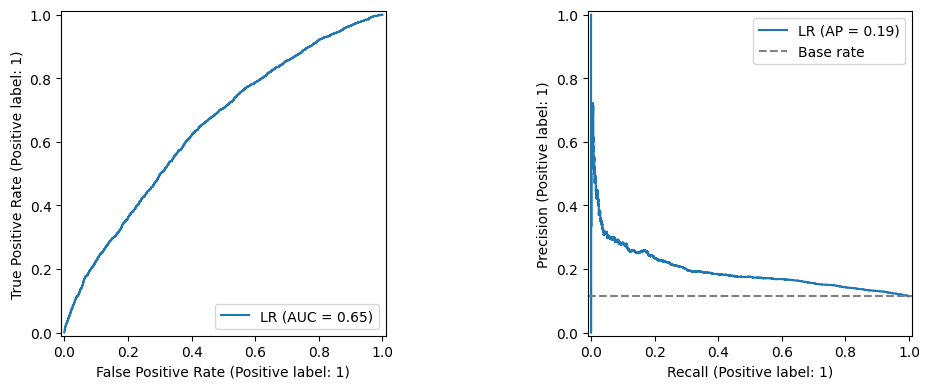

In [6]:
best = models["LR (class weights)"]
p = best.predict_proba(Xva)[:, 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(yva, p, ax=ax[0], name="LR")
PrecisionRecallDisplay.from_predictions(yva, p, ax=ax[1], name="LR")
ax[1].axhline(yva.mean(), ls="--", color="gray", label="Base rate")
ax[1].legend()
fig.tight_layout(); fig.savefig("results/baseline_curves.png", dpi=150)